In [1]:
# verification
from pyscf import gto, dft, scf
import numpy as np
from scipy.linalg import eigh, block_diag

bas = 'stuttgartrsc'

molcoords = """
Cr1          1.130432197164135     0.000000000000000     0.000000000000000    ;
Cr2          -0.565216098582067    0.978983000000000     0.000000000000000    ;
Cr3          -0.565216098582067    -0.978983000000000    0.000000000000000    ;
"""

molS = gto.Mole()
molS.atom = molcoords
molS.spin=18 # ^ Spin
molS.basis = bas # ^ Basis
molS.ecp = bas
molS.build()

mf = molS.GKS(xc='')
dm = np.load('dm.npy')
vxcmat = np.load('vmat.npy')
ex = np.load('Ex.npy')

total_E = mf.energy_tot(dm=dm) + ex
print('Total Energy:', total_E)

fock = mf.get_fock(dm=dm) + vxcmat
S = molS.intor('int1e_ovlp')
moe = eigh(fock, block_diag(S, S))[0]
print('MO Energies:', moe[:8])

Total Energy: [-258.37672115]
MO Energies: [-2.8140323  -2.8140323  -2.80003337 -2.69692506 -2.69692506 -2.68465732
 -1.732952   -1.732952  ]


In [2]:
SCFResult = '''
converged SCF energy = -258.376721148272  <S^2> = 4.0016806  2S+1 = 4.1239207
mo_energy = [-2.81451743e+00 -2.69746325e+00 -1.73342381e+00 -1.69571545e+00
mo_energy = [-2.81451743e+00 -2.69746325e+00 -1.73342381e+00 -1.69571545e+00
mo_energy = [-2.68519761e+00 -1.70493751e+00 -1.68698121e+00 -1.56952805e+00
mo_energy = [-2.80051951e+00 -1.68543139e+00 -1.57999711e+00 -1.57031239e+00
'''

In [2]:
import matplotlib.pyplot as plt
import sys
sys.path.append('/home/peter/Research/Tools')
from torque import eval_m

coords = np.load('coords.npy')
m = eval_m(molS, dm, coords).T
B = np.load('B.npy').T[-len(coords):]

In [3]:
B110 = np.load('/home/peter/Research/NCNLDFT/code/Test/Cr3Test0422/WSDA/MandB/15_86_110/Results/B.npy').T[-len(coords):]
B74 = np.load('/home/peter/Research/NCNLDFT/code/Test/Cr3Test0422/WSDA/MandB/15_86_74/Results/B.npy').T[-len(coords):]
np.max(np.abs(B110 - B74))

0.00019833276443448344

In [4]:
dm110 = np.load('/home/peter/Research/NCNLDFT/code/Test/Cr3Test0422/WSDA/MandB/15_86_110/Results/dm.npy')
dm74 = np.load('/home/peter/Research/NCNLDFT/code/Test/Cr3Test0422/WSDA/MandB/15_86_74/Results/dm.npy')
np.max(np.abs(dm110 - dm74))

0.00023664038965613102

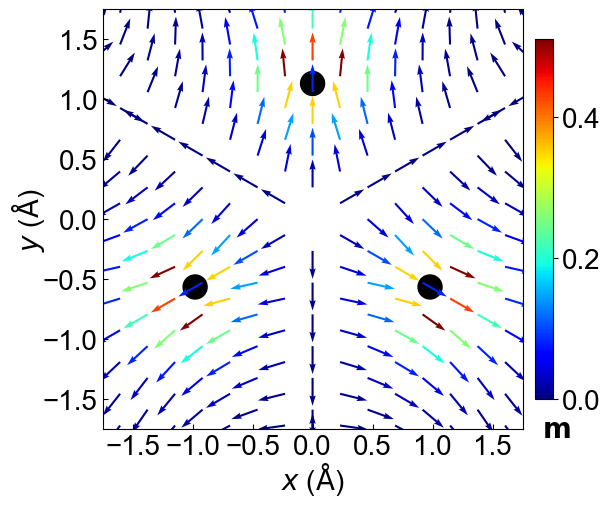

In [5]:
m_mag = np.linalg.norm(m, axis=0)
m_dir = m / m_mag

x = coords[:, 0]
y = coords[:, 1]

x_new = -y * 0.529177
y_new = x * 0.529177
u_new = -m_dir[1]
v_new = m_dir[0]

plt.rcParams['font.family'] = 'Arial'  # 设置字体类型
plt.rcParams['font.size'] = 20         # 设置全局字体大小

fig = plt.figure(figsize=(6, 6))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])
cax = fig.add_axes([0.87, 0.2, 0.03, 0.6])

obstacles = np.array([(1.1304, 0.0), (-0.5652, 0.9789), (-0.5652, -0.9789)])
obstacles_rotated = np.column_stack((-obstacles[:,1], obstacles[:,0]))  # 逆时针旋转90度

for (ox, oy) in obstacles_rotated:
    circle = plt.Circle((ox, oy), 0.1, color='black')
    ax.add_patch(circle)

quiv = ax.quiver(x_new, y_new, u_new, v_new, m_mag, cmap='jet',
                 scale=15, width=0.005, headwidth=3, headlength=5)
quiv.set_clim(0.0, np.max(m_mag))
cbar = plt.colorbar(quiv, ax=ax, cax=cax)
cbar.set_ticks([0.0, 0.2, 0.4])
cbar.ax.yaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))
# cbar.set_label('$|\mathbf{m}|$ (a.u.)')
label_text = '$\mathbf{m}$'
label_y_position = -0.05 # 调整这个值来控制标签和Colorbar底部的距离
cbar.ax.text(1.2, label_y_position, label_text,
            transform=cbar.ax.transAxes, # 使用 cbar.ax 的坐标系
            rotation=0,                  # 水平文本
            ha='center',                 # 水平居中
            va='top',                    # 垂直对齐：文本顶部对齐 y 坐标
            fontsize=plt.rcParams['font.size']) # 确保字体大小一致

ax.set_aspect('equal')
ax.tick_params(axis='both', which='major', direction='in')
ax.set_xlim(-1.75, 1.75)
ax.set_ylim(-1.75, 1.75)
ax.set_xticks(np.arange(-1.5, 2, 0.5))
ax.set_yticks(np.arange(-1.5, 2, 0.5))
ax.set_xlabel('$x$ ($\mathrm{\AA}$)', labelpad=0.)
ax.set_ylabel('$y$ ($\mathrm{\AA}$)', labelpad=-3)
# plt.tight_layout()
# plt.show()
plt.savefig('m.png', dpi=600, bbox_inches='tight', pad_inches=0.05)

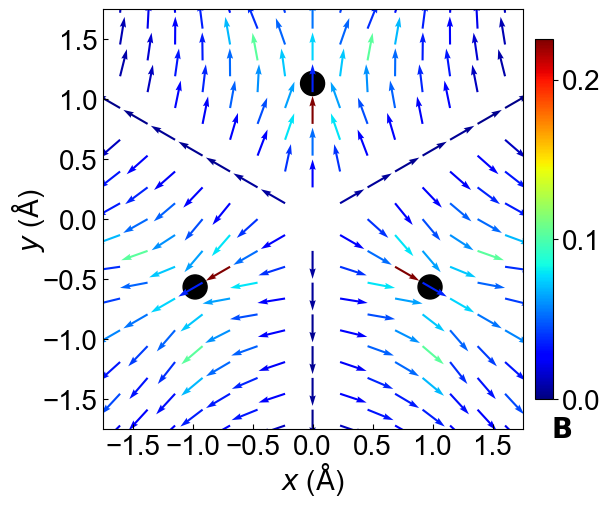

In [6]:
# symmetrize B field
from scipy.spatial.transform import Rotation as R

rm3d = R.from_rotvec(np.array([0.0, 0.0, np.pi*2/3])).as_matrix()
B = np.load('B.npy').T[-len(coords):]
B_new = np.zeros_like(B)
for i in range(len(coords)):
    coord = coords[i]
    coord_r1 = (rm3d @ coord.T).T
    coord_r2 = (rm3d @ rm3d @ coord.T).T

    s1 = R.from_rotvec(np.array([0.0, 1.0, 0.0]) * np.pi).as_matrix()
    s1 = s1 @ (-np.eye(3))
    coord_r3 = (s1 @ coord.T).T

    s2 = R.from_rotvec(np.array([np.sqrt(3)/2, 0.5, 0.0]) * np.pi).as_matrix()
    s2 = s2 @ (-np.eye(3))
    coord_r4 = (s2 @ coord.T).T

    s3 = R.from_rotvec(np.array([np.sqrt(3)/2, -0.5, 0.0]) * np.pi).as_matrix()
    s3 = s3 @ (-np.eye(3))
    coord_r5 = (s3 @ coord.T).T

    where1 = np.where(np.all(np.isclose(coords, coord_r1), axis=1))
    where2 = np.where(np.all(np.isclose(coords, coord_r2), axis=1))
    where3 = np.where(np.all(np.isclose(coords, coord_r3), axis=1))
    where4 = np.where(np.all(np.isclose(coords, coord_r4), axis=1))
    where5 = np.where(np.all(np.isclose(coords, coord_r5), axis=1))

    B1 = (rm3d.T @ B[where1].T).T
    B2 = (rm3d.T @ rm3d.T @ B[where2].T).T
    B3 = (s1.T @ B[where3].T).T
    B4 = (s2.T @ B[where4].T).T
    B5 = (s3.T @ B[where5].T).T

    B_new[i] = (B1 + B2 + B3 + B4 + B5 + B[i]) / 6

B = B_new.T
B_mag = np.linalg.norm(B, axis=0)
B_dir = B / B_mag

x = coords[:, 0]
y = coords[:, 1]

x_new = -y * 0.529177
y_new = x * 0.529177
u_new = -B_dir[1]
v_new = B_dir[0]

fig = plt.figure(figsize=(6, 6))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])
cax = fig.add_axes([0.87, 0.2, 0.03, 0.6])

obstacles = np.array([(1.1304, 0.0), (-0.5652, 0.9789), (-0.5652, -0.9789)])
obstacles_rotated = np.column_stack((-obstacles[:,1], obstacles[:,0]))  # 逆时针旋转90度

for (ox, oy) in obstacles_rotated:
    circle = plt.Circle((ox, oy), 0.1, color='black')
    ax.add_patch(circle)

quiv = ax.quiver(x_new, y_new, u_new, v_new, B_mag, cmap='jet',
                 scale=15, width=0.005, headwidth=3, headlength=5)
quiv.set_clim(0.0, np.max(B_mag))
cbar = plt.colorbar(quiv, ax=ax, cax=cax)
cbar.set_ticks([0.0, 0.1, 0.2])
cbar.ax.yaxis.set_major_formatter(plt.FormatStrFormatter('%.1f'))
# cbar.set_label('$|\mathbf{B}_{\mathrm{xc}}|$ (a.u.)')
label_text = '$\mathbf{B}$'
label_y_position = -0.05 # 调整这个值来控制标签和Colorbar底部的距离
cbar.ax.text(1.5, label_y_position, label_text,
            transform=cbar.ax.transAxes, # 使用 cbar.ax 的坐标系
            rotation=0,                  # 水平文本
            ha='center',                 # 水平居中
            va='top',                    # 垂直对齐：文本顶部对齐 y 坐标
            fontsize=plt.rcParams['font.size']) # 确保字体大小一致

ax.set_aspect('equal')
ax.tick_params(axis='both', which='major', direction='in')
ax.set_xlim(-1.75, 1.75)
ax.set_ylim(-1.75, 1.75)
ax.set_xticks(np.arange(-1.5, 2, 0.5))
ax.set_yticks(np.arange(-1.5, 2, 0.5))
ax.set_xlabel('$x$ ($\mathrm{\AA}$)', labelpad=0.)
ax.set_ylabel('$y$ ($\mathrm{\AA}$)', labelpad=-3)
# plt.show()
plt.savefig('B.png', dpi=600, bbox_inches='tight', pad_inches=0.05)

In [4]:
M = m
torquex = M[1] * B[2] - M[2] * B[1]
torquey = M[2] * B[0] - M[0] * B[2]
torquez = M[0] * B[1] - M[1] * B[0]
T = np.array([torquex, torquey, torquez])

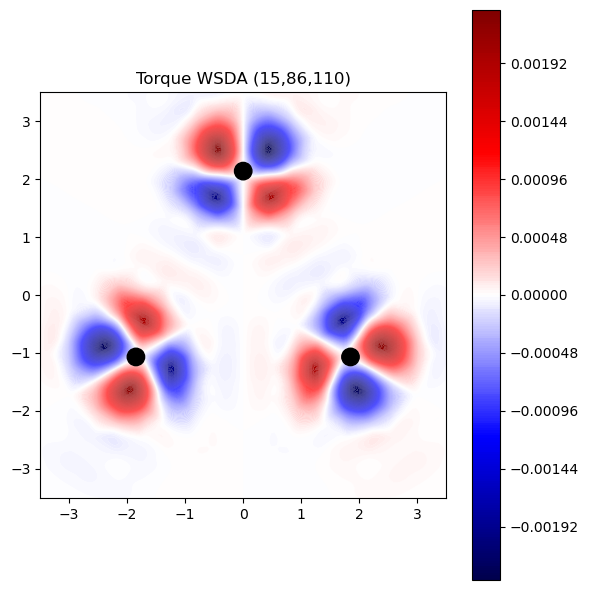

In [5]:
from matplotlib.tri import Triangulation, UniformTriRefiner

# ── 1. 构建 & 细分三角网 ───────────────────────────────────────────────────────
triang = Triangulation(x_new, y_new)

# subdiv=3 ⇒ 每条边三等分，原三角被切成 64 个小三角；可以调大/调小
refiner = UniformTriRefiner(triang)
refined_triang, T_refined = refiner.refine_field(T[2], subdiv=3)

# ── 2. 画图 ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# (1) 填色图：levels 越多 → 颜色越平滑
tricont = ax.tricontourf(
    refined_triang, T_refined,
    levels=300,          # 颜色层级
    cmap='seismic',
    antialiased=True
)

# (2) 障碍物圆圈——一定要 **在 tricontourf 之后** 再画，且设 zorder
obstacles = np.array([
    ( 1.1304,  0.0   ),
    (-0.5652,  0.9789),
    (-0.5652, -0.9789)
]) / 0.529177
obstacles_rotated = np.column_stack((-obstacles[:, 1], obstacles[:, 0]))  # 逆时针 90°

for (ox, oy) in obstacles_rotated:
    circle = plt.Circle((ox, oy), 0.15, color='black', zorder=10)
    ax.add_patch(circle)

# (3) 其它美化
ax.set_aspect('equal')
ax.set_xlim(-3.5, 3.5)
ax.set_ylim(-3.5, 3.5)
ax.set_title("Torque WSDA (15,86,110)")

# 单独给第一次 tricontourf 的返回值上色条
fig.colorbar(tricont, ax=ax)

plt.tight_layout()
plt.show()


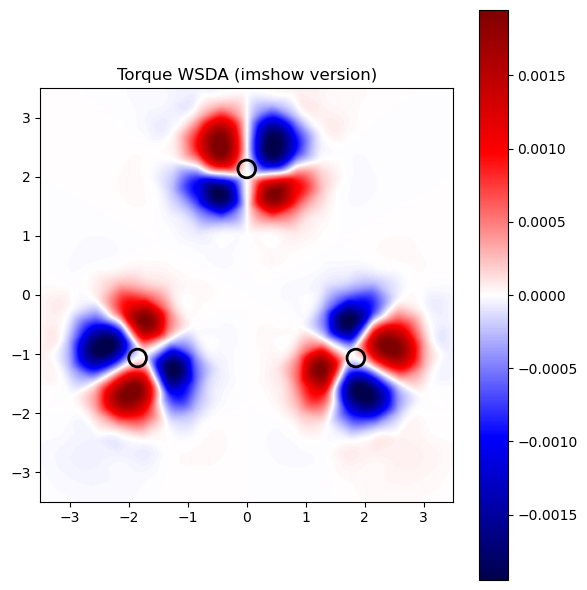

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata   # 如果不用 SciPy，可用 matplotlib.mlab.griddata/RBF

# ── 0. 规则网格设置 ───────────────────────────────────
nx = ny = 500               # ⬅️ 这里改成 400/600/800/1000 都行
x_lin = np.linspace(-3.5, 3.5, nx)
y_lin = np.linspace(-3.5, 3.5, ny)
Xi, Yi = np.meshgrid(x_lin, y_lin)

# ── 1. 把散点数据插值到规则网格 ───────────────────────
# x_new, y_new, T[2] 仍是你的原始散点数据
Ti = griddata(
    points=np.column_stack((x_new, y_new)),
    values=T[2],
    xi=(Xi, Yi),
    method='cubic'          # 'linear' 更快，'nearest' 最快；出版图建议 'cubic'
)

# ── 2. 用 imshow 绘图 ─────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

im = ax.imshow(
    Ti,
    origin='lower',         # meshgrid + imshow 默认左下角是 (0,0)
    extent=[-3.5, 3.5, -3.5, 3.5],
    cmap='seismic',
    vmin=np.nanmin(T[2]),   # 手动设 vmin/vmax 可保持同一配色
    vmax=np.nanmax(T[2]),
    interpolation='bilinear'  # 让像素再平滑一点，可选 'nearest'
)

# 障碍物圆圈（与前文相同）
for (ox, oy) in obstacles_rotated:
    circle = plt.Circle((ox, oy), 0.15, facecolor='none',
                        edgecolor='black', linewidth=2, zorder=10)
    ax.add_patch(circle)

ax.set_aspect('equal')
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
ax.set_title("Torque WSDA (imshow version)")

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()
